# 01.PyTorch Workflow Fundamentals
The workflow steps can be repeated and changed depending on the problem you're working on.<br>
Specifically, we're going to cover:
| Topic | Contents |
| :--- | :--- |
| **1. Getting data ready** | Data can be almost anything but to get started we're going to create a simple straight line |
| **2. Building a model** | Here we'll create a model to learn patterns in the data, we'll also choose a **loss function, optimizer** and build a **training loop**. |
| **3. Fitting the model to data (training)** | We've got data and a model, now let's let the model (try to) find patterns in the (**training**) data. |
| **4. Making predictions and evaluating a model (inference)** | Our model's found patterns in the data, let's compare its findings to the actual (**testing**) data. |
| **5. Saving and loading a model** | You may want to use your model elsewhere, or come back to it later, here we'll cover that. |
| **6. Putting it all together** | Let's take all of the above and combine it. |

In [31]:
import torch
import torch.nn as nn       # nn contains all of PyTorch building blocks for Neural Networks
import matplotlib.pyplot as plt
from pathlib import Path

# check pyTorch Version
torch.__version__

'2.4.1+cu121'

## 1. Data (Preparing & Loading)

In [32]:
# Create (Known) Parameters
weight = 0.7
bias = 0.3

# Create Data
start = 0
end = 1
step = 0.02

X = torch.arange(start=start, end=end, step=step).unsqueeze(1)
y = weight * X + bias

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [33]:
# Split the data into train/dev(val--> if needed)/test sets
train_split = int(0.8 * len(X))            # 80% of data for training, that means 20% for test

X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

In [34]:
# Visualize the data
def plot_predictions(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None):

    plt.figure(figsize=(10, 7))

    # Training points
    plt.scatter(train_data, train_labels, c='b', s=6, label='Training Data')

    # Testing points
    plt.scatter(test_data, test_labels, c='r', s=6, label='Test Data')

    # For predictions on The test in the future (from our built model)
    if predictions != None:
        plt.scatter(test_data, predictions, c='g', s=6, label='Predictions')

    # Show the legend
    plt.legend(prop={'size':14})

    plt.grid(visible=True)
    plt.xlabel("X Values")
    plt.ylabel("Y Values")

    plt.show()

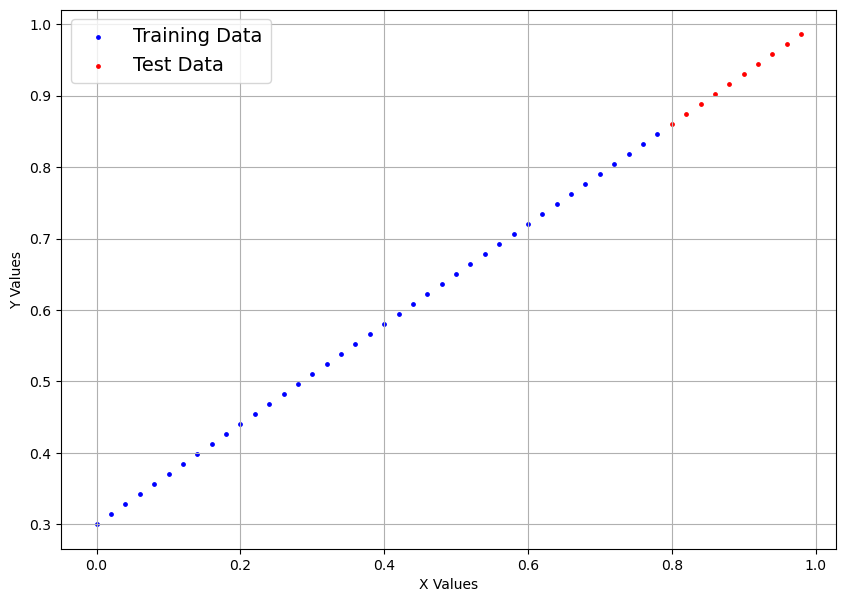

In [35]:
plot_predictions(train_data=X_train,
                train_labels=y_train,
                test_data=X_test,
                test_labels=y_test)

## 2. Build Model

In [36]:
# Build a basic Linear Regression Model

class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()

        # initialize Parameters (Randomly)
        self.weight = nn.Parameter(torch.rand(1,                    # <- start with random weights (this will get adjusted as the model learns)
                                            dtype=torch.float,
                                            requires_grad=True))    # <- can we update this value with gradient descent?))

        self.bias = nn.Parameter(torch.rand(1,                      # <- start with random weights (this will get adjusted as the model learns)
                                            dtype=torch.float,
                                            requires_grad=True))# <- can we update this value with gradient descent?))

    # Forward Function Defines the computations in the Model
    def forward(self, x:torch.Tensor) -> torch.Tensor:      # <- "x" is the input data (e.g. training/testing features)
        return self.weight * x + self.bias # <- this is the linear regression formula (y = m*x + b)


### PyTorch Model Building Essential

PyTorch provides four core modules essential for building almost any neural network architecture:
* `torch.nn`
* `torch.optim`
* `torch.utils.data.Dataset`
* `torch.utils.data.DataLoader`

---

#### Core Building Blocks

| PyTorch Module / Component | What Does It Do? |
| :--- | :--- |
| **`torch.nn`** | Contains all the foundational building blocks for computational graphs (a series of computations executed in a specific sequence). |
| **`torch.nn.Parameter`** | Stores tensors designed for use with `nn.Module`. When `requires_grad=True`, gradients are automatically tracked and computed for gradient descent (**Autograd**). |
| **`torch.nn.Module`** | The base class for all neural network modules. Any custom model must subclass `nn.Module` and implement a `forward()` method. |
| **`torch.optim`** | Contains optimization algorithms (e.g., SGD, Adam) that adjust the parameters stored in `nn.Parameter` to minimize the loss function. |
| **`def forward()`** | Required in every `nn.Module` subclass; defines the explicit forward pass computation applied to input tensors. |

---

#### Simplified Intuition

Almost every component inside a PyTorch neural network originates from `torch.nn`:

* **`nn.Module`**: The larger structural building blocks (layers).
* **`nn.Parameter`**: The smaller learnable values, such as weights and biases (grouped inside `nn.Module`).
* **`forward()`**: Defines how input tensors flow through the layers and computations.
* **`torch.optim`**: Drives learning by updating the values inside `nn.Parameter`.

### Checking The Contents of PyTorch Model

In [37]:
# Create a model instance (object) of out prev LinearRegression Class
## set the manual seed, since nn.parameters are randomly initialized
torch.manual_seed(42)

## Create the object
model_0 = LinearRegression()

## parameters
print(list(model_0.parameters()))           ## list the parameters
model_0.state_dict()                        ## List named parameters

[Parameter containing:
tensor([0.8823], requires_grad=True), Parameter containing:
tensor([0.9150], requires_grad=True)]


OrderedDict([('weight', tensor([0.8823])), ('bias', tensor([0.9150]))])

### Making Predictions Using `torch.inference_model()`

In [38]:
# Making some predictions, by passing the test data to the model
# will pass it through the forward() and make the computations on test and produce a (random) prediction
# random cause the parameters still initialized randomly didn't change
with torch.inference_mode():
    y_preds = model_0(X_test)


# Note: in older PyTorch code you might also see torch.no_grad()
# with torch.no_grad():
#   y_preds = model_0(X_test)

In [39]:
# Check the predictions
print(f"Number of testing samples: {len(X_test)}")
print(f"Number of predictions made: {len(y_preds)}")
print(f"Predicted values:\n{y_preds}")

Number of testing samples: 10
Number of predictions made: 10
Predicted values:
tensor([[1.6208],
        [1.6385],
        [1.6561],
        [1.6738],
        [1.6914],
        [1.7090],
        [1.7267],
        [1.7443],
        [1.7620],
        [1.7796]])


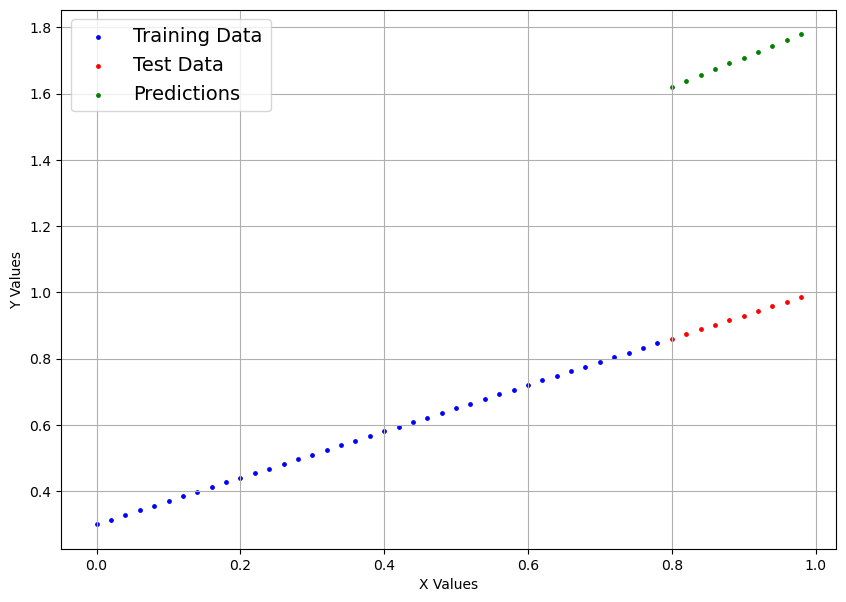

In [40]:
plot_predictions(predictions=y_preds)

## 3. Train Model

In [41]:
# Creating a Loss Function & Optimizer

## Loss Function
loss_fn = nn.L1Loss()           # MAE is the same as L1Loss

## Optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

### Creating an Optimization Loop in PyTorch

#### Training Loop
| Step | Step Name                                   | Description                                                                                                | Code Example                      |
| :--- | :------------------------------------------ | :--------------------------------------------------------------------------------------------------------- | :-------------------------------- |
| 1    | Forward pass                                | Passes the training data through the model to execute its `forward()` computation.                         | `model(x_train)`                  |
| 2    | Calculate the loss                          | Compares the model's predictions against the true labels to measure the error.                             | `loss = loss_fn(y_pred, y_train)` |
| 3    | Zero gradients                              | Resets the optimizer's gradients to zero (as they accumulate by default) for the current step.             | `optimizer.zero_grad()`           |
| 4    | Backpropagation                             | Computes the loss gradient for every trainable parameter (`requires_grad=True`) via **backpropagation**.   | `loss.backward()`                 |
| 5    | Update the optimizer (**gradient descent**) | Adjusts the trainable parameters (`requires_grad=True`) using the calculated gradients to reduce the loss. | `optimizer.step()`                |

#### Testing Loop
| Step | Step Name                               | Description                                                                                   | Code Example                     |
| :--- | :-------------------------------------- | :-------------------------------------------------------------------------------------------- | :------------------------------- |
| 1    | Forward pass                            | Passes the testing data through the model to execute its `forward()` computation.             | `model(x_test)`                  |
| 2    | Calculate the loss                      | Compares the model's predictions against the ground truth to evaluate test error.             | `loss = loss_fn(y_pred, y_test)` |
| 3    | Calculate evaluation metrics (optional) | Computes additional evaluation metrics alongside the loss (such as accuracy on the test set). | Custom functions                 |

In [42]:
# train through 100 epochs and evaluate

epochs = 200

train_loss_values = []
test_loss_values = []
epoch_count = []

for epoch in range(epochs):

    ### Training

    # Put Model in training mode (The Default State Of The Model)
    model_0.train()

    # 1. Forward pass on training data using forward() method inside model
    y_pred = model_0(X_train)

    # 2. Calc The Loss
    loss = loss_fn(y_pred, y_train)

    # 3. zero the optimizer
    optimizer.zero_grad(set_to_none=True)

    # 4. Loss Backwards
    loss.backward()

    # 5. Update the params by taking a step
    optimizer.step()


    ### Testing

    # Put Model in evaluating mode
    model_0.eval()

    # 1. Forwarding
    test_pred = model_0(X_test)

    # 2. Calc Loss
    test_loss = loss_fn(test_pred, y_test.type(torch.float)) # predictions come in torch.float datatype, so comparisons need to be done with tensors of the same type

    # Print out what's happening
    if epoch % 10 == 0:
            epoch_count.append(epoch)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")

Epoch: 0 | MAE Train Loss: 0.6860889196395874 | MAE Test Loss: 0.7637526988983154 
Epoch: 10 | MAE Train Loss: 0.5708791017532349 | MAE Test Loss: 0.6290428042411804 
Epoch: 20 | MAE Train Loss: 0.45566922426223755 | MAE Test Loss: 0.4943329691886902 
Epoch: 30 | MAE Train Loss: 0.34045934677124023 | MAE Test Loss: 0.35962313413619995 
Epoch: 40 | MAE Train Loss: 0.2252494841814041 | MAE Test Loss: 0.2249133139848709 
Epoch: 50 | MAE Train Loss: 0.1100396141409874 | MAE Test Loss: 0.09020347893238068 
Epoch: 60 | MAE Train Loss: 0.009724985808134079 | MAE Test Loss: 0.020998019725084305 
Epoch: 70 | MAE Train Loss: 0.006216754671186209 | MAE Test Loss: 0.014099234715104103 
Epoch: 80 | MAE Train Loss: 0.002788322512060404 | MAE Test Loss: 0.005826681852340698 
Epoch: 90 | MAE Train Loss: 0.007095950655639172 | MAE Test Loss: 0.00754010071977973 
Epoch: 100 | MAE Train Loss: 0.007095950655639172 | MAE Test Loss: 0.00754010071977973 
Epoch: 110 | MAE Train Loss: 0.007095950655639172 | MA

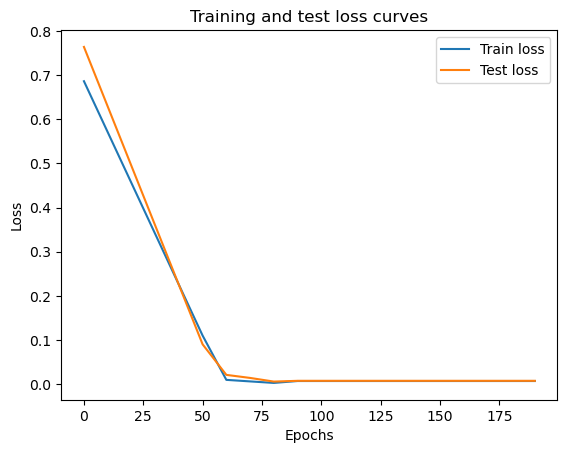

In [43]:
# Plot the loss curves
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

In [44]:
# Inspect the model (find the model learned parameters)
print(f"The model learning the following values of weight and bias: \n{model_0.state_dict()}")
print(f"\nAnd the original values of weight an bias are: \n{weight, bias}")

The model learning the following values of weight and bias: 
OrderedDict([('weight', tensor([0.6977])), ('bias', tensor([0.3080]))])

And the original values of weight an bias are: 
(0.7, 0.3)


## 4.Making predictions with a trained PyTorch model (inference)

In [45]:
# 1. Set the model in evaluation mode
model_0.eval()

# 2. Setup the inference mode context manager
with torch.inference_mode():
  # 3. Make sure the calculations are done with the model and data on the same device
  # in our case, we haven't setup device-agnostic code yet so our data and model are
  # on the CPU by default.
  # model_0.to(device)
  # X_test = X_test.to(device)
  y_preds = model_0(X_test)
y_preds

tensor([[0.8661],
        [0.8801],
        [0.8940],
        [0.9080],
        [0.9220],
        [0.9359],
        [0.9499],
        [0.9638],
        [0.9778],
        [0.9917]])

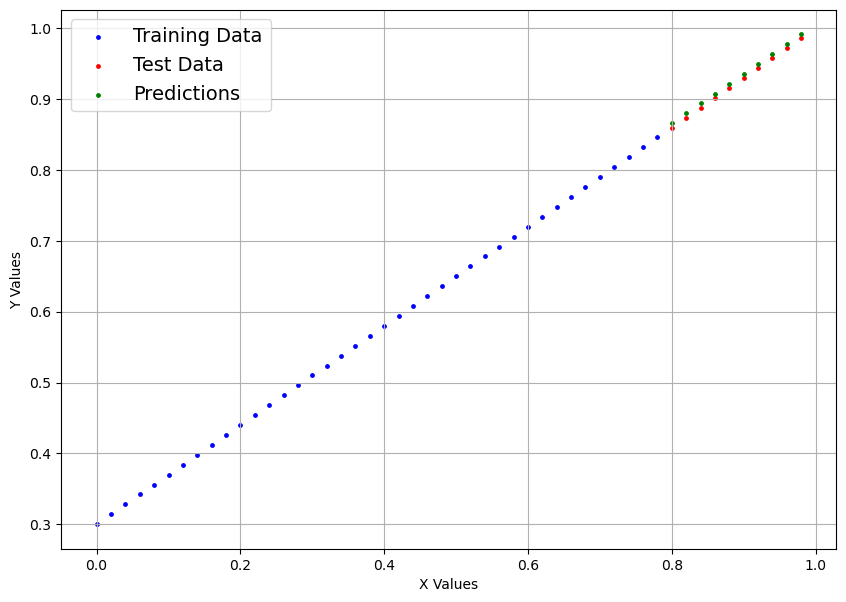

Predictions Loss: 0.00593


In [46]:
# Plot the predictions
plot_predictions(
    train_data=X_train,
    train_labels=y_train,
    test_data=X_test,
    test_labels=y_test,
    predictions=y_preds
)

# Calc the loss (different between actual and predicted values)
predictions_loss = loss_fn(y_preds, y_test.type(torch.float))
print(f"Predictions Loss: {predictions_loss:.5f}")

## 5. Saving and Loading a PyTorch Model
| PyTorch Method | What Does It Do? |
| :--- | :--- |
| `torch.save` | Saves a serialized object to disk using Python's `pickle` utility. Models, tensors, and various other Python objects like dictionaries can be saved using `torch.save`. |
| `torch.load` | Uses `pickle`'s unpickling features to deserialize and load pickled Python object files (like models, tensors, or dictionaries) into memory. You can also set which device to load the object to (CPU, GPU, etc.). |
| `torch.nn.Module.load_state_dict` | Loads a model's parameter dictionary (`model.state_dict()`) using a saved `state_dict()` object. |

### Saving a PyTorch model's `state_dict()`

In [47]:
# 1.Create Models Directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Create Model Save Path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save The Model sate_dict
print(F"Saving the model State to: {MODEL_SAVE_PATH}")
torch.save(obj= model_0.state_dict(),                   # only saving the state_dict() only saves the models learned parameters, (Specifically a Dictionary of model Parameters)
           f=MODEL_SAVE_PATH)

Saving the model State to: models/01_pytorch_workflow_model_0.pth


In [48]:
# Check the saved file path
!ls -l models/01_pytorch_workflow_model_0.pth

-rw-rw-r-- 1 ae ae 1680 Nov 10 14:11 models/01_pytorch_workflow_model_0.pth


### Loading a Saved PyTorch Models `state_dict()`


In [49]:
# Since we saved only a sate_dict(), a dictionary of model parameters not a model

# Instantiate a new instance of our model (this will be instantiated with random weights)
loaded_model_0 = LinearRegression()

# Load the state_dict of our saved model (this will update the new instance of our model with trained weights)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH, weights_only=True))

<All keys matched successfully>

In [50]:
# Test The Loaded Model

# 1. Put the loaded model into evaluation mode
loaded_model_0.eval()

# 2. Use the inference mode context manager to make predictions
with torch.inference_mode():
    loaded_model_preds = loaded_model_0(X_test) # perform a forward pass on the test data with the loaded model

In [51]:
# Compare previous model predictions with loaded model predictions (these should be the same)
y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## 6. Putting It All Together

In [52]:
# Import PyTorch and matplotlib
import torch
from torch import nn # nn contains all of PyTorch's building blocks for neural networks
import matplotlib.pyplot as plt

# Check PyTorch version
torch.__version__

'2.4.1+cu121'

In [53]:
# Set the device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


### 6.1 Data

In [54]:
# Create weights
weight = 0.7
bias = 0.3

# Create range
start = 0
end = 1
step = 0.02

# Create the data (X, y)
X = torch.arange(start=start, end=end, step=step)
y = weight * X + bias

X[:10], y[:10]

(tensor([0.0000, 0.0200, 0.0400, 0.0600, 0.0800, 0.1000, 0.1200, 0.1400, 0.1600,
         0.1800]),
 tensor([0.3000, 0.3140, 0.3280, 0.3420, 0.3560, 0.3700, 0.3840, 0.3980, 0.4120,
         0.4260]))

In [55]:
# Split data
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

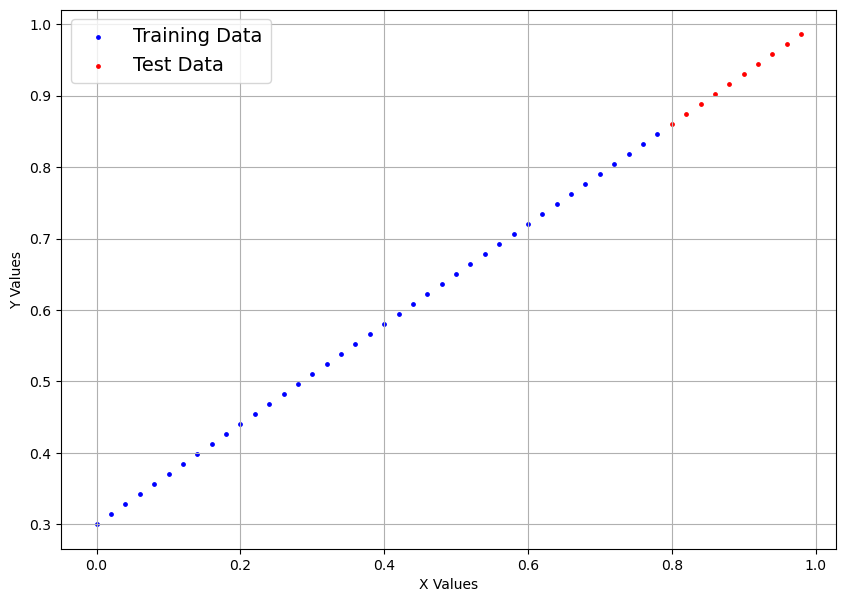

In [56]:
# Note: If you've reset your runtime, this function won't work,
# you'll have to rerun the cell above where it's instantiated.
plot_predictions(X_train, y_train, X_test, y_test)

### 6.2 Building a PyTorch Linear Model

In [57]:
# Create a Linear Regression Model in PyTorch
class LinearRegressionV2(nn.Module):
    def __init__(self):
        super().__init__()

        # Using nn.Linear() for creating Model parameters
        self.linear_layer = nn.Linear(in_features=1, out_features=1)

    # forward() defines The all computations in the model
    def forward(self, X:torch.Tensor) -> torch.Tensor:
        return self.linear_layer(X)

# Set the manual seed when creating the model (this isn't always needed but is used for demonstrative purposes, try commenting it out and seeing what happens)
torch.manual_seed(42)
model_1 = LinearRegressionV2()
model_1, model_1.state_dict()

(LinearRegressionV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [58]:
# Check The model device
next(model_1.parameters()).device

device(type='cpu')

In [59]:
model_1.to(device)
next(model_1.parameters()).device

device(type='cuda', index=0)

### 6.3 Training

In [60]:
# Creating a Loss Function
criterion = nn.L1Loss()

# Creating an Optimizer
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.01)

In [61]:
# Set The epochs
epochs = 1000

train_loss = []
total = []
correct = []

# Put the data also to gpu and ensure they have 2D shapes for nn.Linear
X_train = X_train.unsqueeze(1).to(device)
y_train = y_train.unsqueeze(1).to(device)
X_test = X_test.unsqueeze(1).to(device)
y_test = y_test.unsqueeze(1).to(device)

for epoch in range(epochs):
  ### Training
  model_1.train()

  # 1. Forward Pass
  y_pred = model_1(X_train)

  # 2. Calc loss
  loss = criterion(y_pred, y_train)

  # 3. clear the optimizer
  optimizer.zero_grad(set_to_none=True)

  # 4. Backward over the loss
  loss.backward()

  # 5. update the params
  optimizer.step()


  ### Testing
  model_1.eval()

  # 1. Forward pass
  with torch.inference_mode():
    test_pred = model_1(X_test)

    # 2. Calc The test loss
    test_loss = criterion(test_pred, y_test)

  if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Train loss: {loss} | Test loss: {test_loss}")

Epoch: 0 | Train loss: 0.5551779866218567 | Test loss: 0.5739762187004089
Epoch: 100 | Train loss: 0.006215683650225401 | Test loss: 0.014086711220443249
Epoch: 200 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 300 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 400 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 500 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 600 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 700 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 800 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoch: 900 | Train loss: 0.0012645035749301314 | Test loss: 0.013801801018416882


In [62]:
# Find our model's learned parameters
from pprint import pprint # pprint = pretty print, see: https://docs.python.org/3/library/pprint.html
print("The model learned the following values for weights and bias:")
pprint(model_1.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

And the original values for weights and bias are:
weights: 0.7, bias: 0.3


### 6.4 Making Predictions

In [63]:
# Predict
with torch.inference_mode():
  y_preds = model_1(X_test)

y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

> **Note**: Many data science libraries such as pandas, matplotlib and NumPy aren't capable of using data that is stored on GPU. So you might run into some issues when trying to use a function from one of these libraries with tensor data not stored on the CPU. To fix this, you can call `.cpu()` on your target tensor to return a copy of your target tensor on the CPU.

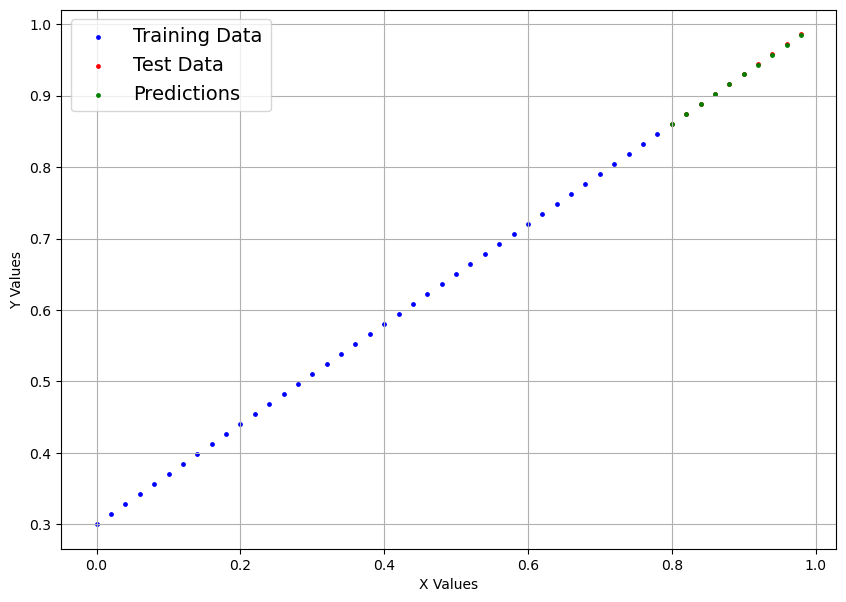

In [64]:
# Plot The data and the predictions
# plot_predictions(predictions=y_preds) # -> won't work... data not on CPU

# Put data on the CPU and plot it
plot_predictions(predictions=y_preds.cpu())

### 6.5 Saving and Loading a Model

In [66]:
# 1. Creating models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Creating model saving path
MODEL_NAME = "01_pytorch_workflow_model_1.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# Save the model state_dict()
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(), f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_1.pth


In [69]:
# Load The model

## Instantiate a fresh instant of LinearRegressionV2 class
loaded_model_1 = LinearRegressionV2()

# Load model state_dict()
loaded_model_1.load_state_dict(torch.load(f=MODEL_SAVE_PATH, weights_only=True))

# Put model to target device (if your data is on GPU, model will have to be on GPU to make predictions)
loaded_model_1.to(device)

print(f"Loaded model: {loaded_model_1}")
print(F"Model on device: {next(loaded_model_1.parameters()).device}")

Loaded model: LinearRegressionV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)
Model on device: cuda:0


In [70]:
# Evaluate Loaded Model
with torch.inference_mode():
    loaded_model_1.eval()
    loaded_model_1_pred = loaded_model_1(X_test)

loaded_model_1_pred == y_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')